# 03 · A/B experiment evaluation

**Synthetic fixed-horizon experiment.** We evaluate the predeclared primary outcome, effect size and harm thresholds. Read `docs/experiment_plan.md` before interpreting outputs.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import polars as pl
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / "config/simulation.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.common import config
pl.Config.set_tbl_rows(16)
pl.Config.set_tbl_cols(14)
print("Polars:", pl.__version__)


Polars: 2.0.0


In [2]:
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from src.analyse_experiment import compare_binary
cfg=config()['experiment']
df=pl.read_parquet(ROOT/'data/processed/user_metrics.parquet')
summary=json.loads((ROOT/'reports/experiment_summary.json').read_text())

## 1. Sample-size planning
Baseline 45%, 1 pp absolute MDE, 80% power and two-sided alpha .05. This is a planning approximation for independent users.

In [3]:
effect=abs(proportion_effectsize(cfg['baseline_activation']+cfg['minimum_detectable_effect'],cfg['baseline_activation']))
n=NormalIndPower().solve_power(effect_size=effect,power=cfg['power'],alpha=cfg['alpha'],ratio=1)
print('Required users per arm:',int(np.ceil(n)))
print('Observed assignment sizes:',df.group_by('variant').len().to_dicts())

Required users per arm: 38926
Observed assignment sizes: [{'variant': 'treatment', 'len': 125098}, {'variant': 'control', 'len': 124902}]


## 2. Sample-ratio mismatch
A failed allocation check would block interpreting the primary result until investigated. The threshold is .001, set before analysis.

In [4]:
counts=df.group_by('variant').len().sort('variant')
observed=counts['len'].to_numpy()
expected=np.array([1-cfg['allocation'],cfg['allocation']])*observed.sum()
stat,p=stats.chisquare(observed,f_exp=expected)
display(counts); print('SRM statistic:',stat,'p:',p,'passes:',p>=cfg['srm_alpha'])

SRM statistic: 0.153664 p: 0.6950582138022077 passes: True


variant,len
str,u32
"""control""",124902
"""treatment""",125098


## 3. Independent user-level aggregation
Count each customer once. Failed payments and payments outside seven days do not count.

In [5]:
arm=df.filter(pl.col('mature_7d')).group_by('variant').agg(pl.len().alias('n'),pl.col('activated_7d').sum().alias('activated')); display(arm)

variant,n,activated
str,u32,i32
"""control""",124902,60496
"""treatment""",125098,65440


## 4. Primary effect, interval and test
The Newcombe interval estimates treatment minus control. The z test evaluates equal proportions. Relative lift and percentage-point lift are different quantities.

In [6]:
c=arm.filter(pl.col('variant')=='control').row(0,named=True)
t=arm.filter(pl.col('variant')=='treatment').row(0,named=True)
primary=compare_binary(c['activated'],c['n'],t['activated'],t['n'])
display(pl.DataFrame([primary]))
print(f"Absolute lift: {primary['difference']*100:.3f} pp")
print(f"Relative lift: {primary['relative_lift']:.2%}")
print(f"95% CI: [{primary['ci_low']*100:.3f}, {primary['ci_high']*100:.3f}] pp")

Absolute lift: 3.876 pp
Relative lift: 8.00%
95% CI: [3.484, 4.268] pp


control_n,treatment_n,control_success,treatment_success,control_rate,treatment_rate,difference,relative_lift,ci_low,ci_high,p_value
i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64
124902,125098,60496,65440,0.484348,0.52311,0.038762,0.08003,0.034844,0.042678,1.1033e-83


## 5. Secondary efficacy outcomes
Verification and funding are secondary. Holm correction is applied across those two p-values; their displayed 95% intervals remain descriptive, unadjusted intervals.

metric,control_n,treatment_n,control_success,treatment_success,control_rate,treatment_rate,difference,relative_lift,ci_low,ci_high,p_value,holm_p
str,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""activated_7d""",124902,125098,60496,65440,0.484348,0.52311,0.038762,0.08003,0.034844,0.042678,1.1033e-83,null
"""verified_7d""",124902,125098,92687,97467,0.742078,0.779125,0.037047,0.049924,0.033705,0.040389,1.8258e-104,1.8258e-104
"""funded_7d""",124902,125098,73333,79240,0.587124,0.633423,0.046299,0.078857,0.042479,0.050117,1.6015e-124,3.2030e-124
"""support_7d""",124902,125098,8782,7735,0.070311,0.061832,-0.00848,-0.120601,-0.010427,-0.006533,1.4115e-17,null
"""failure_7d""",124902,125098,16099,14462,0.128893,0.115605,-0.013288,-0.103091,-0.015856,-0.01072,3.6268e-24,null
"""fraud_30d""",124902,125098,478,502,0.003827,0.004013,0.000186,0.048564,-0.000305,0.000677,0.457138,null


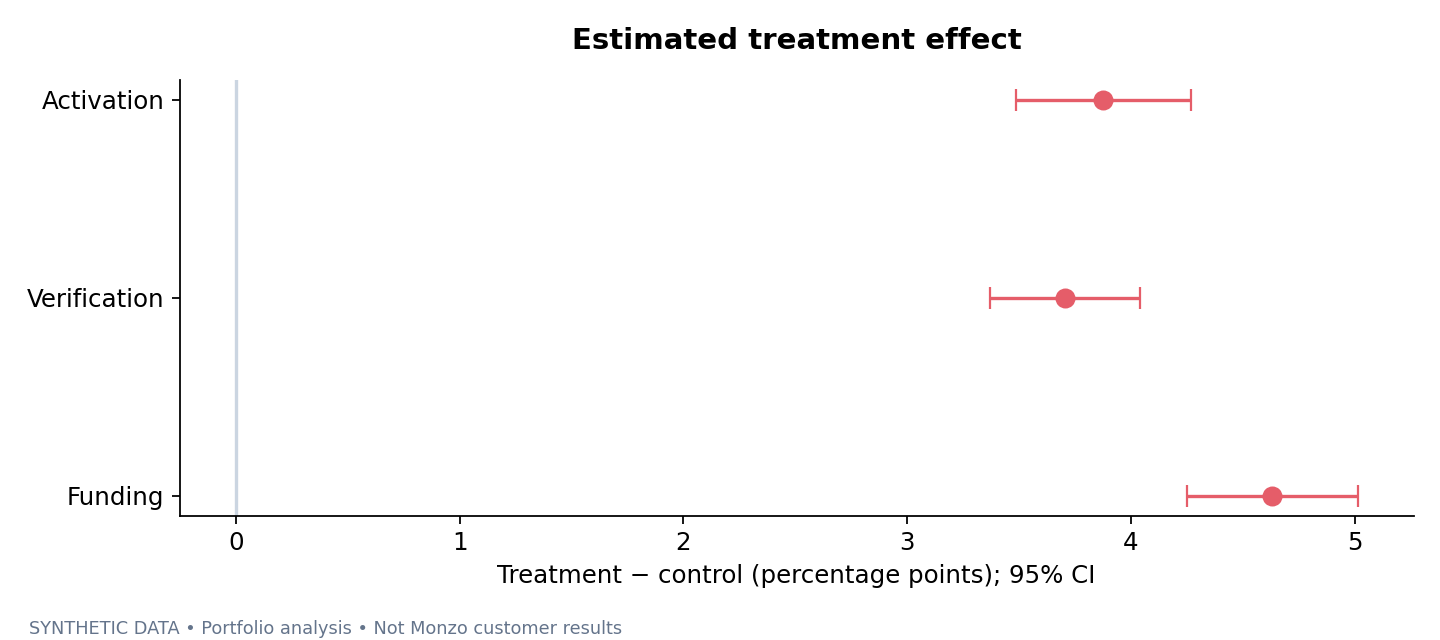

In [7]:
results=pl.read_csv(ROOT/'data/dashboard/experiment_results.csv'); display(results); display(Image(filename=str(ROOT/'reports/figures/02_experiment_effects.png')))

## 6. Guardrail non-inferiority logic
For each harm metric, the simultaneous upper bound must be below its predeclared margin. A nonsignificant harm test does not imply safety.

In [8]:
guards=pl.read_csv(ROOT/'data/dashboard/guardrails.csv'); display(guards); print('All guardrails pass:',guards['passes'].all())

All guardrails pass: True


metric,difference,upper_bound,margin,passes
str,f64,f64,f64,bool
"""support_7d""",-0.00848,-0.006366,0.005,true
"""failure_7d""",-0.013288,-0.0105,0.005,true
"""fraud_30d""",0.000186,0.000719,0.001,true


## 7. Rare outcomes and financial meaning
Fraud flags are alerts, not confirmed fraud, chargebacks or loss. We report per-assigned-user exposure. Higher transaction volume can increase flag counts even without a change in per-transaction flag probability.

In [9]:
display(results.filter(pl.col('metric')=='fraud_30d').select('control_n','control_success','treatment_n','treatment_success','difference','ci_low','ci_high'))

control_n,control_success,treatment_n,treatment_success,difference,ci_low,ci_high
i64,i64,i64,i64,f64,f64,f64
124902,478,125098,502,0.000186,-0.000305,0.000677


## 8. Restricted time to activation
Every user contributes min(time to first payment, seven days); non-activators contribute seven days. With complete seven-day follow-up this estimates restricted mean time without first payment. It avoids selection on post-treatment activation.

In [10]:
display(df.group_by('variant').agg(pl.col('restricted_days_to_payment').mean().alias('mean_restricted_days'),pl.col('restricted_days_to_payment').std().alias('sd')))
display(pl.DataFrame([summary['restricted_time']]))

variant,mean_restricted_days,sd
str,f64,f64
"""control""",4.970499,2.357796
"""treatment""",4.789292,2.390786


control_days,treatment_days,difference_days,ci_low,ci_high
f64,f64,f64,f64,f64
4.970499,4.789292,-0.181206,-0.199821,-0.162592


## 9. Practical effect and simulated decision

In [11]:
print(summary['decision'])
print('Primary CI lower bound clears 0.5 pp:',primary['ci_low']>cfg['practical_lift'])
print('Additional activations per 100,000 under simulation assumptions:',round(primary['difference']*100000))
print('This is not a revenue forecast or actual business result.')

SIMULATED LAUNCH CRITERIA MET
Primary CI lower bound clears 0.5 pp: True
Additional activations per 100,000 under simulation assumptions: 3876
This is not a revenue forecast or actual business result.


## 10. Sensitivity to the acceptable fraud increase
This is a transparent scenario analysis, not a way to change the predeclared pass/fail decision after looking at results.

In [12]:
upper=guards.filter(pl.col('metric')=='fraud_30d')['upper_bound'].item()
display(pl.DataFrame({'hypothetical_margin_pp':[.025,.05,.10,.20]}).with_columns((pl.col('hypothetical_margin_pp')/100>upper).alias('would_pass_given_current_upper_bound')))
print('Predeclared margin remains 0.10 pp.')

Predeclared margin remains 0.10 pp.


hypothetical_margin_pp,would_pass_given_current_upper_bound
f64,bool
0.025,false
0.05,false
0.1,true
0.2,true


## 11. What we can and cannot conclude

In [13]:
display(Markdown((ROOT/'reports/experiment_readout.md').read_text()))

# Experiment readout: digital banking onboarding

**SYNTHETIC PORTFOLIO STUDY — not a Monzo experiment or real customer evidence.**

## Decision

**SIMULATED LAUNCH CRITERIA MET.** Within the configured simulation, seven-day activation was 48.43% in control and 52.31% in treatment. The estimated effect was **3.88 percentage points** (95% Newcombe CI 3.48 to 4.27 pp), or 8.00% relative lift.

This corresponds to about 3,876 additional activations per 100,000 assigned users under these synthetic assumptions. It is not a revenue estimate, realised business impact, or forecast for Monzo.

## Design and integrity

- Randomisation unit: user; treatment assigned before onboarding; analysis retains all eligible assigned users.
- Population: 250,000 users (124,902 control; 125,098 treatment). No post-treatment filtering.
- Enrolment: 84 days; 30-day follow-up per user; ingestion watermark allows an additional 72 hours.
- Planning assumptions: 45% baseline, 1 pp detectable improvement, two-sided alpha .05, 80% power. Required sample: 38,926 per arm. The 250,000-user design exceeds this to support learning with large data, not because this many users are necessary for the primary test.
- Sample-ratio mismatch p=0.69506; alert threshold 0.001. Baseline categorical balance is available in the dashboard extracts.
- Primary activation comes from successful payment transactions, not client event counts.

## Results

Rates and differences below are proportions; multiply differences by 100 for percentage points.

| metric | control_rate | treatment_rate | difference | ci_low | ci_high | p_value | holm_p |
| --- | --- | --- | --- | --- | --- | --- | --- |
| activated_7d | 0.48435 | 0.52311 | 0.03876 | 0.03484 | 0.04268 | 0.00000 | — |
| verified_7d | 0.74208 | 0.77913 | 0.03705 | 0.03370 | 0.04039 | 0.00000 | 0.00000 |
| funded_7d | 0.58712 | 0.63342 | 0.04630 | 0.04248 | 0.05012 | 0.00000 | 0.00000 |
| support_7d | 0.07031 | 0.06183 | -0.00848 | -0.01043 | -0.00653 | 0.00000 | — |
| failure_7d | 0.12889 | 0.11561 | -0.01329 | -0.01586 | -0.01072 | 0.00000 | — |
| fraud_30d | 0.00383 | 0.00401 | 0.00019 | -0.00030 | 0.00068 | 0.45714 | — |

Primary efficacy uses a pooled two-proportion z test and Newcombe confidence interval. Verification and funding use Holm-adjusted secondary p-values; their displayed intervals are unadjusted descriptive intervals. Guardrail decision-making uses the separate simultaneous upper bounds below, not their two-sided p-values.

## Guardrails

| metric | difference | upper_bound | margin | passes |
| --- | --- | --- | --- | --- |
| support_7d | -0.00848 | -0.00637 | 0.00500 | True |
| failure_7d | -0.01329 | -0.01050 | 0.00500 | True |
| fraud_30d | 0.00019 | 0.00072 | 0.00100 | True |

Three one-sided upper bounds use Bonferroni alpha .05/3, providing at least 95% family-wise coverage. Passing means the upper bound is below a predeclared acceptable increase: support and onboarding failure 0.5 pp; fraud flags 0.1 pp. These thresholds are illustrative assumptions, not approved bank risk limits. A nonsignificant difference alone does not establish safety.

## Time to first payment

Mean time without a first payment, restricted to seven days, was 4.970 days in control and 4.789 in treatment. Difference: -0.181 days (large-sample 95% CI -0.200, -0.163). Non-activators contribute seven days; this avoids comparing only the selected users who activated. This is an exploratory endpoint.

## Product interpretation and next action

The simulated treatment changes verification completion, funding propensity and verification speed. Funnel movement is consistent with those programmed mechanisms. It does not independently discover that clearer instructions cause these outcomes in real banking customers.

For a real pilot, validate the instrumentation, agree risk margins with product and risk teams, and run a fixed-horizon randomised experiment. Continue monitoring confirmed fraud losses, support costs and longer-term customer value. Cohort return rates and channel/device cuts here are exploratory; no segment-specific rollout is justified by these cuts alone.

## Limits

- Synthetic mechanisms encode the treatment effect; this project demonstrates analysis and engineering, not product validation.
- Fraud flags are transaction-linked proxy alerts, not confirmed fraud or financial loss. More payments can produce more flags; the per-user measure captures total assigned-user exposure.
- Thirty days cannot establish long-term profitability, losses or lifetime value.
- Background app visits are simplified; weekly return rates should not be interpreted as realistic banking benchmarks.
- Injected corrupt records are ancillary telemetry. The study does not simulate unobserved business outcomes or differential missingness.
- No operational deployment, real-user experiment, Tableau workbook or GitHub publication has occurred.


## Interview discussion

- Why is assignment the denominator instead of users who completed onboarding?
- Why does a payment exactly seven days after assignment fall outside the window?
- Why does statistical significance not establish commercial value?
- Why do guardrails need acceptable harm thresholds and uncertainty bounds?
- Why do synthetic results not replace real large-scale experimentation experience?
- What would change with partial follow-up, cross-device identity errors, delayed losses or dependent users?